# 01 · Data acquisition & raw profiling (DuckDB)
**CIS 5450 – EV Energy and Thermal Monitoring · Phase 1**

This notebook:
1. Downloads the **TUM Electric Vehicle UDS dataset** (Zenodo, ~620 MB zip) and extracts the 7 per-vehicle Parquet files + `value_overview.csv`.
2. Inspects the raw long-format schema (`vehicle_id, time, value_id, value`) with **DuckDB**; nothing is loaded fully into pandas.
3. Profiles every signal: row counts, coverage per vehicle, value ranges, and sampling interval.
4. Proposes a mapping from raw `value_id`s to the project's canonical column names, saved to `config/signal_map.json`.

**Outputs:** `data/raw/*.parquet`, `data/interim/signal_coverage.csv`, `config/signal_map.json`, figures in `reports/figures/`.

> ⚠️ After running, **open `config/signal_map.json` and review it** (see the checklist at the end). Notebook 02 uses it.

Source: Schreiber et al., *Lab-to-Field Gap in Battery Aging Studies*, eTransportation 27 (2026) 100518 · github.com/TUMFTM/electric-vehicle-uds-dataset · licence CC BY-NC 4.0.

In [1]:
# Run once per environment (safe to re-run)
%pip install -q duckdb pyarrow pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# project root = folder that contains src/ev_pipeline.py (works from /notebooks or the root)
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "src" / "ev_pipeline.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import ev_pipeline as ev

P = ev.project_paths(ROOT)
# Raw data (~1.2 GB) can live outside OneDrive: set env var EV_RAW_DIR before starting Jupyter
RAW_DIR = Path(os.environ.get("EV_RAW_DIR", P["raw"]))
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
warnings.filterwarnings("ignore", category=FutureWarning)

def savefig(name):
    plt.savefig(P["figures"] / f"{name}.png", dpi=130, bbox_inches="tight")

print("Project root:", ROOT)
print("Raw data dir:", RAW_DIR)

import duckdb
print("duckdb", duckdb.__version__)

Project root: C:\Users\sumit\OneDrive\Desktop\Big_Data\Project
Raw data dir: C:\Users\sumit\OneDrive\Desktop\Big_Data\Project\data\raw


duckdb 2.0.0


## 1. Download & extract

In [3]:
DELETE_ZIP_AFTER_EXTRACT = True   # saves ~620 MB once the parquet files are extracted
ZIP = RAW_DIR / "electric-vehicle-uds-dataset-public.zip"
RAW_DIR.mkdir(parents=True, exist_ok=True)

files = ev.locate_raw_files(RAW_DIR)
if not files["parquet"] or files["overview"] is None:
    print("Downloading from Zenodo (one-time, ~620 MB)...")
    try:
        ev.download_file(ev.ZENODO_URL, ZIP)
    except Exception as e:
        raise RuntimeError(
            f"Download failed ({e}). Download manually from https://zenodo.org/records/17532823 "
            f"and put the zip at {ZIP}, then re-run this cell.")
    md5 = ev.md5sum(ZIP)
    print("md5", md5, "OK" if md5 == ev.ZENODO_MD5 else f"(expected {ev.ZENODO_MD5} - file may differ/corrupt)")
    files = ev.extract_needed(ZIP, RAW_DIR)
    if DELETE_ZIP_AFTER_EXTRACT and files["parquet"]:
        ZIP.unlink()
else:
    print("Raw files already present - skipping download.")

print("value_overview:", files["overview"])
pd.DataFrame({"file": [p.name for p in files["parquet"]],
              "size_MB": [round(p.stat().st_size / 1e6, 1) for p in files["parquet"]]})

Raw files already present - skipping download.
value_overview: C:\Users\sumit\OneDrive\Desktop\Big_Data\Project\data\raw\electric-vehicle-uds-dataset-public\data\value_overview.csv


,file,size_MB
0,CUP1.parquet,77.3
1,CUP2.parquet,33.7
2,CUP3.parquet,8.8
3,CUP4.parquet,44.2
4,CUP5.parquet,29.8
5,ID1.parquet,338.8
6,ID2.parquet,311.9


## 2. Raw schema

In [4]:
con = duckdb.connect()
first = files["parquet"][0].as_posix()
schema = con.sql(f"DESCRIBE SELECT * FROM read_parquet('{first}')").df()
display(schema[["column_name", "column_type"]])
con.sql(f"SELECT * FROM read_parquet('{first}') LIMIT 5").df()

,column_name,column_type
0,vehicle_id,VARCHAR
1,time,TIMESTAMP_NS
2,value_id,BIGINT
3,value,DOUBLE


,vehicle_id,time,value_id,value
0,CUP1,2087-03-07 15:45:43.011,4,4.68
1,CUP1,2087-03-07 15:45:43.163,1200,402.50
2,CUP1,2087-03-07 15:45:43.211,1200,402.50
3,CUP1,2087-03-07 15:45:43.229,4,4.65
4,CUP1,2087-03-07 15:45:43.374,1200,402.50


In [5]:
# Detect the role of each raw column (robust to small naming differences)
types = dict(zip(schema.column_name, schema.column_type))
lower = {c.lower(): c for c in types}
TIME_COL  = lower.get("time") or next(c for c in types if any(k in c.lower() for k in ("time", "date", "ts")))
ID_COL    = lower.get("value_id") or next(c for c in types if "id" in c.lower() and "vehicle" not in c.lower())
VEH_COL   = next((c for c in types if "vehicle" in c.lower()), None)
VALUE_COL = lower.get("value") or next(c for c in types if c not in (TIME_COL, ID_COL, VEH_COL))

time_unit = None
if types[TIME_COL].upper().startswith(ev.NUMERIC_TYPES):
    tmax = con.sql(f'SELECT max("{TIME_COL}") FROM read_parquet(\'{first}\')').fetchall()[0][0]
    time_unit = ev.infer_time_unit(float(tmax))

# Valid time window: the logger clock occasionally produces impossible dates (e.g. year 2087).
# The TUM fleet was logged 2021-2023, so everything outside 2020-2024 is dropped.
TS_MIN, TS_MAX = "2020-01-01", "2024-12-31"
cfg = {"time_col": TIME_COL, "time_type": types[TIME_COL], "time_unit": time_unit,
       "id_col": ID_COL, "id_type": types[ID_COL], "value_col": VALUE_COL, "vehicle_col": VEH_COL,
       "ts_min": TS_MIN, "ts_max": TS_MAX}
cfg

{'time_col': 'time',
 'time_type': 'TIMESTAMP_NS',
 'time_unit': None,
 'id_col': 'value_id',
 'id_type': 'BIGINT',
 'value_col': 'value',
 'vehicle_col': 'vehicle_id',
 'ts_min': '2020-01-01',
 'ts_max': '2024-12-31'}

In [6]:
# One DuckDB view over all 7 files: base(vehicle_id, ts, vid, val)
ev.configure_duckdb(con, P["interim"] / "duckdb_tmp")
veh_files = {p.stem: p for p in files["parquet"]}
con.sql(ev.build_base_view_sql(veh_files, cfg, view_name="base_all", apply_time_window=False))
con.sql(ev.build_base_view_sql(veh_files, cfg))   # view 'base' = valid time window only

bad_ts = con.sql(f"""SELECT vehicle_id, count(*) AS n_rows_outside_window, min(ts) AS min_ts, max(ts) AS max_ts
                     FROM base_all WHERE ts NOT BETWEEN TIMESTAMP '{TS_MIN}' AND TIMESTAMP '{TS_MAX}'
                     GROUP BY 1""").df()
print("Rows with impossible timestamps (dropped):"); display(bad_ts)

per_vehicle = con.sql("""
    SELECT vehicle_id,
           count(*)               AS n_rows,
           count(DISTINCT vid)    AS n_signals,
           min(ts)                AS first_ts,
           max(ts)                AS last_ts,
           count(DISTINCT CAST(ts AS DATE)) AS active_days
    FROM base GROUP BY 1 ORDER BY 1
""").df()
print(f"Total rows: {per_vehicle.n_rows.sum():,}  |  vehicles: {len(per_vehicle)}")
if per_vehicle.first_ts.min().year < 2015:
    print("WARNING: timestamps before 2015 -> time unit guess may be wrong; set cfg['time_unit'] manually.")
per_vehicle

Rows with impossible timestamps (dropped):


,vehicle_id,n_rows_outside_window,min_ts,max_ts
0,CUP1,812,2087-03-07 15:45:43.011,2087-03-07 15:46:37.899


Total rows: 98,060,402  |  vehicles: 7


,vehicle_id,n_rows,n_signals,first_ts,last_ts,active_days
0,CUP1,8658680,12,2022-11-15 09:37:08.846,2023-04-24 15:10:02.500,109
1,CUP2,3743488,12,2022-11-21 08:43:12.514,2023-05-04 21:36:48.278,70
2,CUP3,986864,12,2022-11-17 09:35:16.957,2023-04-23 12:23:51.029,30
3,CUP4,4943471,12,2022-11-15 09:42:31.880,2023-04-14 14:23:20.269,91
4,CUP5,3305981,12,2022-11-10 17:06:10.156,2023-04-23 18:38:08.398,82
5,ID1,40401700,15,2021-02-01 20:20:34.114,2023-06-13 07:50:10.952,369
6,ID2,36020218,12,2021-07-26 14:16:10.139,2023-10-10 10:55:11.233,339


## 3. Signal dictionary & coverage
`value_overview.csv` maps each `value_id` to a signal name/unit. Below we join it with per-signal statistics computed in DuckDB.
The proposal noted 29 signals of which ~14 are empty; this table confirms that.

In [7]:
overview = ev.read_value_overview(files["overview"])
with pd.option_context("display.max_rows", 100, "display.max_colwidth", 80):
    display(overview.drop(columns=["label"]))

,value_id,name_de,name_en,variable_name,unit,min_val,max_val,sampling_interval_ms
0,15,Umgebungslufttemperatur,Ambient air temperature,ambient_air_temp,°C,-40.0,215.0,10000.0
1,4,Geschwindigkeit,vehicle speed,vehicle_speed,km/h,0.0,254.0,200.0
2,1200,Packspannung,pack voltage,hv_battery_voltage,V,0.0,1000.0,200.0
3,1205,PTC1 Strom,PTC1 current,ptc1_current,A,0.0,100.0,1000.0
4,1206,PTC2 Strom,PTC2 current,ptc2_current,A,0.0,100.0,1000.0
5,1207,PTC Spannung,PTC voltage,ptc_voltage,V,0.0,1000.0,1000.0
6,1208,Pack Temp. Min.,HV Battery Temp min.,hv_temp_min,°C,-40.0,100.0,10000.0
7,1209,Pack Temp. Max.,HV Battery Temp max.,hv_temp_max,°C,-40.0,100.0,10000.0
8,43,Innenraumtemperatur,Interior Temperature,interior_temp,°C,-100.0,100.0,10000.0
9,56,Leistung HV Nebenverbraucher,Power HV Aux,hv_aux_power,W,-20000.0,20000.0,1000.0


In [8]:
stats = con.sql("""
    SELECT vid AS value_id,
           count(*)                     AS n_rows,
           count(val)                   AS n_valid,
           count(DISTINCT vehicle_id)   AS n_vehicles,
           min(val)                     AS min,
           approx_quantile(val, 0.01)   AS p01,
           approx_quantile(val, 0.50)   AS p50,
           approx_quantile(val, 0.99)   AS p99,
           max(val)                     AS max,
           avg(val)                     AS mean,
           stddev(val)                  AS std,
           count(*) FILTER (WHERE val = 0)     AS n_exact_zero,
           count(*) FILTER (WHERE val >= 1000) AS n_ge_1000
    FROM base GROUP BY 1
""").df()
coverage = overview[["value_id", "label"]].merge(stats, on="value_id", how="outer")
coverage[["n_rows", "n_valid", "n_vehicles"]] = coverage[["n_rows", "n_valid", "n_vehicles"]].fillna(0).astype(int)
coverage["usable"] = coverage["n_valid"] > 0
coverage = coverage.sort_values("n_valid", ascending=False).reset_index(drop=True)
coverage.to_csv(P["interim"] / "signal_coverage.csv", index=False)

print(f"Signals in overview: {len(overview)} | with data: {coverage.usable.sum()} | empty: {(~coverage.usable).sum()}")
with pd.option_context("display.max_rows", 100, "display.max_colwidth", 50, "display.float_format", "{:,.2f}".format):
    display(coverage)

Signals in overview: 29 | with data: 15 | empty: 14


,value_id,label,n_rows,n_valid,n_vehicles,min,p01,p50,p99,max,mean,std,n_exact_zero,n_ge_1000,usable
0,1200,Packspannung | pack voltage | hv_battery_volta...,66055361,66055361,7,0.00,372.50,419.88,458.37,"8,642.50",419.97,24.47,"1,552.00",65.00,True
1,4,Geschwindigkeit | vehicle speed | vehicle_spee...,17272952,17272952,7,0.00,0.00,18.52,142.84,428.68,37.26,44.21,"6,565,348.00",0.00,True
2,56,Leistung HV Nebenverbraucher | Power HV Aux | ...,5724440,5724440,7,0.00,0.00,306.33,"5,327.56","25,400.00",778.53,"1,151.38","1,506,967.00","1,715,184.00",True
3,900,Ladezustand | SOC | hv_soc | %,1668449,1668449,7,0.00,14.33,70.36,100.00,101.60,68.43,23.41,60.00,0.00,True
4,1269,Kühlmitteltemperatur Inverter Einlass | coolan...,1311954,1311954,7,-30.68,1.97,19.88,37.06,51.25,20.75,8.27,76.00,0.00,True
5,1265,Rotortemperatur Hinten | rotor temp rear motor...,1225990,1225990,7,-11.82,1.80,26.94,98.15,111.57,31.85,23.01,63.00,0.00,True
6,961,Temp. Stator (Hinterachse) | temp stator (rear...,1202063,1202063,7,-6.42,1.57,22.72,54.84,88.04,23.16,11.50,88.00,0.00,True
7,1272,Temperatur HV Pack Einlass | Battery pack inle...,1144895,1144895,7,0.00,0.00,11.00,121.08,"1,023.98",19.98,82.78,"39,246.00","7,285.00",True
8,1273,Temperatur HV Pack Auslass | Battery pack outl...,1140258,1140258,7,0.00,0.00,11.00,103.80,"1,023.98",19.78,81.13,"40,816.00","6,919.00",True
9,15,Umgebungslufttemperatur | Ambient air temperat...,616932,616932,7,-11.00,-5.96,8.09,29.98,39.50,9.45,8.25,"11,412.00",0.00,True


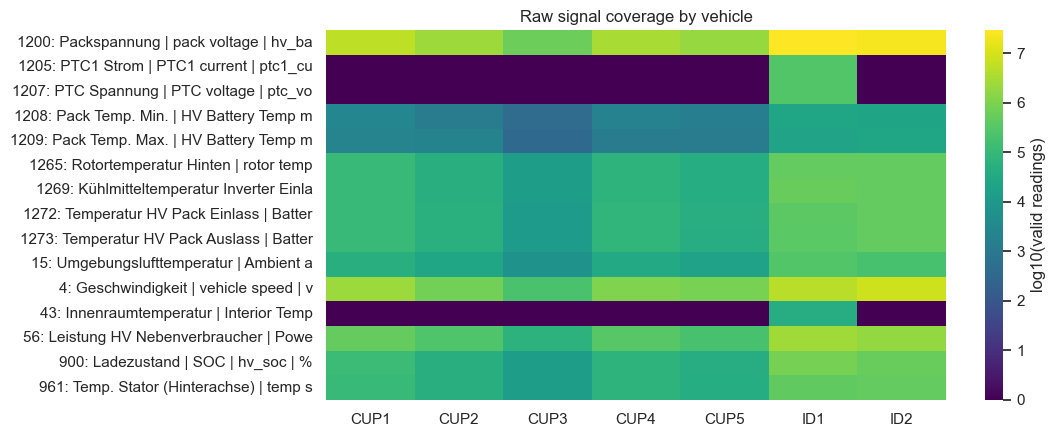

In [9]:
# Rows per vehicle x signal (log scale) - shows which signals are missing for which vehicle
cnt = con.sql("SELECT vehicle_id, vid AS value_id, count(val) AS n FROM base GROUP BY 1, 2").df()
lab = dict(zip(coverage.value_id, coverage.label.fillna("").str.slice(0, 35)))
mat = cnt.pivot(index="value_id", columns="vehicle_id", values="n").fillna(0)
mat.index = [f"{i}: {lab.get(i, '')}" for i in mat.index]
plt.figure(figsize=(10, max(4, 0.32 * len(mat))))
sns.heatmap(np.log10(mat + 1), cmap="viridis", cbar_kws={"label": "log10(valid readings)"})
plt.title("Raw signal coverage by vehicle"); plt.xlabel(""); plt.ylabel("")
savefig("01_signal_coverage_heatmap"); plt.show()

In [10]:
# Typical sampling interval per signal (computed on the smallest vehicle that has the most signals,
# because a window function over the 40M-row vehicles needs a lot of memory)
big = per_vehicle.sort_values(["n_signals", "n_rows"], ascending=[False, True]).vehicle_id.iloc[0]
interval = con.execute("""
    WITH s AS (
        SELECT vid, epoch_ms(ts) - lag(epoch_ms(ts)) OVER (PARTITION BY vid ORDER BY ts) AS d_ms
        FROM base WHERE vehicle_id = ?)
    SELECT vid AS value_id,
           approx_quantile(d_ms, 0.5) / 1000.0 AS median_interval_s,
           approx_quantile(d_ms, 0.9) / 1000.0 AS p90_interval_s
    FROM s WHERE d_ms IS NOT NULL GROUP BY 1
""", [big]).df()
coverage = coverage.merge(interval, on="value_id", how="left")
coverage.to_csv(P["interim"] / "signal_coverage.csv", index=False)
print("Vehicle used:", big)
coverage.loc[coverage.usable, ["value_id", "label", "median_interval_s", "p90_interval_s"]]

Vehicle used: ID1


,value_id,label,median_interval_s,p90_interval_s
0,1200,Packspannung | pack voltage | hv_battery_volta...,0.142,0.220
1,4,Geschwindigkeit | vehicle speed | vehicle_spee...,0.220,0.438
2,56,Leistung HV Nebenverbraucher | Power HV Aux | ...,1.020,1.046
3,900,Ladezustand | SOC | hv_soc | %,5.012,5.072
4,1269,Kühlmitteltemperatur Inverter Einlass | coolan...,5.013,5.020
5,1265,Rotortemperatur Hinten | rotor temp rear motor...,5.014,5.046
6,961,Temp. Stator (Hinterachse) | temp stator (rear...,5.014,5.032
7,1272,Temperatur HV Pack Einlass | Battery pack inle...,5.015,10.047
8,1273,Temperatur HV Pack Auslass | Battery pack outl...,5.015,10.063
9,15,Umgebungslufttemperatur | Ambient air temperat...,10.008,10.019


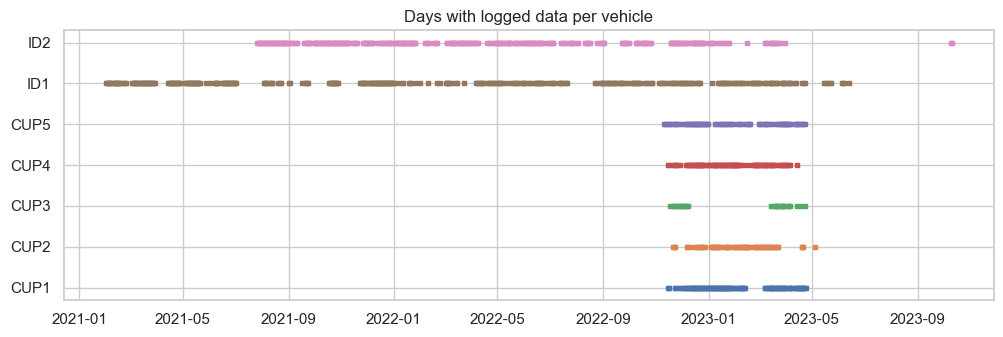

In [11]:
# When was each vehicle logging? (rows per day)
daily = con.sql("SELECT vehicle_id, CAST(ts AS DATE) AS day, count(*) AS n FROM base GROUP BY 1, 2").df()
daily["day"] = pd.to_datetime(daily["day"])
fig, ax = plt.subplots(figsize=(12, 3.5))
for i, (v, g) in enumerate(daily.groupby("vehicle_id")):
    ax.scatter(g["day"], np.full(len(g), i), s=6, marker="s")
ax.set_yticks(range(daily.vehicle_id.nunique()), sorted(daily.vehicle_id.unique()))
ax.set_title("Days with logged data per vehicle")
savefig("01_logging_timeline"); plt.show()

## 4. Propose the signal map → `config/signal_map.json`

In [12]:
OVERWRITE_SIGNAL_MAP = False      # set True to regenerate even if the file has been reviewed
map_path = P["config"] / "signal_map.json"

keep_ids = coverage.loc[coverage.usable, "value_id"].tolist()
if set(ev.TUM_SIGNAL_MAP.values()) <= set(overview.value_id):
    # Known TUM release: use the mapping verified against value_overview.csv
    proposal = {k: (v if v in keep_ids else None) for k, v in ev.TUM_SIGNAL_MAP.items()}
    verified = True
    print("Using verified TUM_SIGNAL_MAP (signals without data are set to None).")
else:
    proposal = ev.propose_signal_map(overview, coverage[["value_id", "n_valid"]])
    verified = False

if map_path.exists() and not OVERWRITE_SIGNAL_MAP and ev.load_json(map_path).get("reviewed"):
    print("signal_map.json exists and is marked reviewed -> keeping it (set OVERWRITE_SIGNAL_MAP=True to replace)")
    config = ev.load_json(map_path)
    config["schema"] = cfg
else:
    config = {"reviewed": verified, "schema": cfg, "signals": proposal, "keep_value_ids": keep_ids,
              "note": "Edit 'signals' if a mapping is wrong, then set reviewed=true."}
ev.save_json(config, map_path)

cinfo = coverage.set_index("value_id")
rows = []
for name, vid in config["signals"].items():
    spec = ev.CANONICAL_SIGNALS.get(name, {})
    r = cinfo.loc[vid] if vid in cinfo.index else None
    lo, hi = ev.VALID_RANGES.get(name, (None, None))
    flag = ""
    if vid is None and spec.get("required"):
        flag = "MISSING (required)"
    elif r is not None and lo is not None and (r.p01 < lo or r.p99 > hi):
        flag = "check range/units"
    rows.append({"canonical": name, "value_id": vid, "raw_label": None if r is None else r.label,
                 "unit_expected": spec.get("unit"), "p01": None if r is None else r.p01,
                 "p50": None if r is None else r.p50, "p99": None if r is None else r.p99, "flag": flag})
mapping_table = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", 60):
    display(mapping_table)
print("Saved", map_path)

Using verified TUM_SIGNAL_MAP (signals without data are set to None).
signal_map.json exists and is marked reviewed -> keeping it (set OVERWRITE_SIGNAL_MAP=True to replace)


,canonical,value_id,raw_label,unit_expected,p01,p50,p99,flag
0,speed,4,Geschwindigkeit | vehicle speed | vehicle_speed | km/h,km/h,0.000000,18.523971,142.838983,
1,soc,900,Ladezustand | SOC | hv_soc | %,%,14.325619,70.362237,100.000000,
2,bat_temp,1209,Pack Temp. Max. | HV Battery Temp max. | hv_temp_max | °C,degC,6.236718,17.315067,35.245746,
3,bat_temp_min,1208,Pack Temp. Min. | HV Battery Temp min. | hv_temp_min | °C,degC,0.000000,15.684624,33.445594,
4,bat_inlet_temp,1272,Temperatur HV Pack Einlass | Battery pack inlet temp | h...,,0.000000,10.999185,121.077299,check range/units
5,bat_outlet_temp,1273,Temperatur HV Pack Auslass | Battery pack outlet temp | ...,,0.000000,10.999427,103.800510,check range/units
6,hv_voltage,1200,Packspannung | pack voltage | hv_battery_voltage | V,V,372.502508,419.881594,458.369168,
7,ambient_temp,15,Umgebungslufttemperatur | Ambient air temperature | ambi...,degC,-5.962985,8.093006,29.984278,
8,interior_temp,43,Innenraumtemperatur | Interior Temperature | interior_te...,,4.341768,22.302703,37.696677,
9,hv_aux_power,56,Leistung HV Nebenverbraucher | Power HV Aux | hv_aux_pow...,,0.000000,306.331494,5327.564741,


Saved C:\Users\sumit\OneDrive\Desktop\Big_Data\Project\config\signal_map.json


## ✅ Review checklist (do this before notebook 02)
Open `config/signal_map.json` and check each canonical signal against `raw_label` and the percentiles above:

| canonical | sanity check |
|---|---|
| `speed` | km/h, p99 roughly 100–160 |
| `soc` | %, values within 0–100 (BMS SOC vs displayed SOC: pick one and tell the team) |
| `bat_temp` | °C, roughly 0–45 |
| `hv_voltage` | V, ~300–450 for a 108s pack |
| `hv_current` | A. **If present, it resolves the proposal's "no battery current" issue**, so energy in Wh becomes possible |
| `motor_rpm`, `ambient_temp`, `odometer` | plausible units |

If a mapping is wrong, change its `value_id` (or set it to `null`), then set `"reviewed": true` and save. Unmapped signals that have data are still carried through as `sig_<id>_<name>` columns.

In [13]:
# Close the connection (notebook 02 opens its own)
con.close()